# Fase 2 — Entendimento dos Dados

**Projeto:** Mapa de Calor e Predição do Risco de Acidentes de Trânsito na Rodovia BR-230  
**Disciplina:** Ciência de Dados — PPGCC / UFMA  
**Equipe:** João Batista Santos Silva Neto, Ricardo Diniz Mendes, Winy Gabrielly Soares de Oliveira  
**Metodologia:** CRISP-DM (Fase 2: Coleta, Descrição, Exploração e Qualidade dos Dados)  
**Recorte Temporal Consolidado:** Quadriênio Pós-Pandemia (**2022 a 2025**)


## 1. Perguntas da exploração

O tema e a rodovia de interesse estão definidos. Para assegurar rigor metodológico e relevância prática ao projeto, estabelecemos como universo analítico a **série histórica consolidada pós-pandemia (2022 a 2025)** ao longo de todo o corredor da Rodovia Transamazônica (BR-230). O ano de 2025 atua adicionalmente como referência para validação externa contra o Anuário Estatístico da PRF e partição prospectiva de teste.

Partimos de cinco perguntas centrais alinhadas ao CRISP-DM:

1. **Concentração Espacial:** As coordenadas geográficas cobrem integralmente a BR-230? Onde os acidentes se acumulam espacialmente (UFs, municípios e quilômetros críticos)?
2. **Padrões Temporais:** Quais são os ciclos de maior volume (ano, mês, dia da semana e hora)? Os horários de pico coincidem com os períodos de maior letalidade?
3. **Fatores da Via e Clima:** Como o tipo de pista (simples vs. dupla), o uso do solo (rural vs. urbano) e as condições meteorológicas afetam a ocorrência e a gravidade dos sinistros?
4. **Severidade e Variável-Alvo:** Onde os acidentes são mais graves? Como formular a variável-alvo para predição de risco de acidentes com vítimas fatais?
5. **Causas e Envolvidos:** Quais são as causas determinantes e tipos de colisão mais recorrentes? Qual é o perfil demográfico das pessoas envolvidas e os veículos mais vulneráveis?


## 2. Leitura dos arquivos

Lemos os CSV da PRF com Pandas, com separador ponto e vírgula, vírgula decimal e codificação ISO-8859-1. Com esse ajuste, latitude e longitude entram como número e os nomes acentuados são preservados. Os arquivos estão na pasta `bases/`, e a leitura funciona com o arquivo aberto em `entendimento_dados/` ou na raiz do projeto.


In [1]:
from pathlib import Path
import io
import zipfile
import requests
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 140)

plt.rcParams.update({
    "figure.figsize": (11, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 13,
})


def localizar_bases() -> Path:
    candidatos = [Path.cwd() / "bases", Path.cwd().parent / "bases"]
    for caminho in candidatos:
        if caminho.exists():
            return caminho.resolve()
    # Se não existir em nenhum local, cria a pasta bases/
    p = Path.cwd() / "bases"
    p.mkdir(parents=True, exist_ok=True)
    return p.resolve()


BASES = localizar_bases()

# Links e IDs oficiais do Portal de Dados Abertos da PRF (Série Pós-Pandemia: 2022 a 2025)
PRF_DOWNLOAD_LINKS = {
    "acidentes2025_todas_causas_tipos.csv": {
        "id": "1-PJGRbfSe7PVjU37A3wTCls_NRXyVGRD",
        "url": "https://drive.google.com/file/d/1-PJGRbfSe7PVjU37A3wTCls_NRXyVGRD/view?usp=sharing/download",
        "grao": "1 linha = 1 pessoa × causa × tipo",
        "ano": 2025,
    },

    # Agrupados por Ocorrência (datatran)
    "datatran2025.csv": {
        "id": "1-G3MdmHBt6CprDwcW99xxC4BZ2DU5ryR",
        "url": "https://drive.google.com/file/d/1-G3MdmHBt6CprDwcW99xxC4BZ2DU5ryR/view?usp=sharing/download",
        "grao": "1 linha = 1 ocorrência",
        "ano": 2025,
    },
    "datatran2024.csv": {
        "id": "14lB0vqMFkaZj8HZ44b0njYgxs9nAN8KO",
        "url": "https://drive.google.com/file/d/14lB0vqMFkaZj8HZ44b0njYgxs9nAN8KO/view?usp=sharing/download",
        "grao": "1 linha = 1 ocorrência",
        "ano": 2024,
    },
    "datatran2023.csv": {
        "id": "1-WO3SfNrwwZ5_l7fRTiwBKRw7mi1-HUq",
        "url": "https://drive.google.com/file/d/1-WO3SfNrwwZ5_l7fRTiwBKRw7mi1-HUq/view?usp=sharing/download",
        "grao": "1 linha = 1 ocorrência",
        "ano": 2023,
    },
    "datatran2022.csv": {
        "id": "1PRQjuV5gOn_nn6UNvaJyVURDIfbSAK4-",
        "url": "https://drive.google.com/file/d/1PRQjuV5gOn_nn6UNvaJyVURDIfbSAK4-/view?usp=sharing/download",
        "grao": "1 linha = 1 ocorrência",
        "ano": 2022,
    },
    # Agrupados por Pessoa (acidentes)
    "acidentes2025.csv": {
        "id": "1-Gp9S-ALO0D1nT8S_OKoC8xlW7BY8F82",
        "url": "https://drive.google.com/file/d/1-Gp9S-ALO0D1nT8S_OKoC8xlW7BY8F82/view?usp=sharing/download",
        "grao": "1 linha = 1 pessoa",
        "ano": 2025,
    },
    "acidentes2024.csv": {
        "id": "14lVfqdoE2gxDliaKZu7K9Mx6847maPtl",
        "url": "https://drive.google.com/file/d/14lVfqdoE2gxDliaKZu7K9Mx6847maPtl/view?usp=sharing/download",
        "grao": "1 linha = 1 pessoa",
        "ano": 2024,
    },
    "acidentes2023.csv": {
        "id": "1-Yk6TV00CH3PixTkKmkoUJQsNiUc5xLm",
        "url": "https://drive.google.com/file/d/1-Yk6TV00CH3PixTkKmkoUJQsNiUc5xLm/view?usp=share_link/download",
        "grao": "1 linha = 1 pessoa",
        "ano": 2023,
    },
    "acidentes2022.csv": {
        "id": "1sd8YIqIHapYaxQeaa-6yeWMdVLTl6hgD",
        "url": "https://drive.google.com/file/d/1sd8YIqIHapYaxQeaa-6yeWMdVLTl6hgD/view?usp=sharing/download",
        "grao": "1 linha = 1 pessoa",
        "ano": 2022,
    },
}


def garantir_base(nome: str, pasta: Path = BASES) -> Path:
    """
    Verifica se a base já existe localmente na pasta bases/.
    Caso não exista, realiza o download automático diretamente do link oficial da PRF
    e descompacta o arquivo CSV, garantindo total reprodutibilidade sem download manual.
    """
    destino = pasta / nome
    if destino.exists():
        return destino

    info = PRF_DOWNLOAD_LINKS.get(nome)
    if not info:
        raise FileNotFoundError(f"Arquivo {nome} não encontrado em {pasta} e link não configurado.")

    file_id = info["id"]
    print(f"Baixando {nome} do portal de dados abertos da PRF (ID: {file_id})...")
    session = requests.Session()
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    r = session.get(url, stream=True, timeout=90)
    for k, v in r.cookies.items():
        if k.startswith("download_warning"):
            url = f"https://drive.google.com/uc?export=download&id={file_id}&confirm={v}"
            r = session.get(url, stream=True, timeout=90)
            break

    if r.status_code != 200:
        raise RuntimeError(f"Falha ao baixar {nome}: HTTP {r.status_code}.")

    try:
        with zipfile.ZipFile(io.BytesIO(r.content)) as zf:
            for membro in zf.namelist():
                if membro.endswith(".csv"):
                    with zf.open(membro) as src, open(destino, "wb") as dst:
                        dst.write(src.read())
                    print(f"✓ Extraído e salvo com sucesso: {destino.name} ({destino.stat().st_size / 1024**2:.1f} MB)")
                    return destino
    except zipfile.BadZipFile:
        with open(destino, "wb") as dst:
            dst.write(r.content)
        print(f"✓ Salvo com sucesso: {destino.name} ({destino.stat().st_size / 1024**2:.1f} MB)")
        return destino


def ler_prf(nome: str, **kwargs) -> pd.DataFrame:
    """Lê um CSV da PRF garantindo previamente sua existência via download automático."""
    caminho = garantir_base(nome)
    return pd.read_csv(
        caminho,
        sep=";",
        decimal=",",
        encoding="latin-1",
        low_memory=False,
        **kwargs,
    )


print("Diretório de bases:", BASES)



def localizar_figuras() -> Path:
    candidatos = [Path.cwd() / "figuras", Path.cwd() / "entendimento_dados" / "figuras"]
    for caminho in candidatos:
        if caminho.exists():
            return caminho.resolve()
    p = Path.cwd() / "entendimento_dados" / "figuras"
    p.mkdir(parents=True, exist_ok=True)
    return p.resolve()


FIGURAS = localizar_figuras()
print("Diretório de figuras:", FIGURAS)


Diretório de bases: /home/rdm/Documentos/Mestrado/Ciencia de dados/Prediction_of_Traffic_Accident_Risk_on_the_BR-230/bases
Diretório de figuras: /home/rdm/Documentos/Mestrado/Ciencia de dados/Prediction_of_Traffic_Accident_Risk_on_the_BR-230/entendimento_dados/figuras


## 3. Coleta inicial dos dados e Reprodutibilidade

Adotamos os dados abertos oficiais da Polícia Rodoviária Federal (PRF). Para conferir **100% de reprodutibilidade científica**, configuramos o catálogo de fontes da série histórica pós-pandemia (2022 a 2025) nos três grãos fornecidos pelo órgão:

- **Por Ocorrência (`datatran`):** 1 linha por sinistro (base principal geoespacial);
- **Por Pessoa (`acidentes`):** 1 linha por indivíduo envolvido (perfil de vítimas e condutores);
- **Todas as Causas e Tipos:** 1 linha por pessoa $\times$ causa $\times$ tipo (detalhamento de causas múltiplas).

A função `garantir_base()` gerencia o download direto a partir dos repositórios oficiais da PRF e descompactação automática na pasta local `bases/`.


In [2]:
catalogo_itens = []
for nome, info in PRF_DOWNLOAD_LINKS.items():
    arquivo_path = BASES / nome
    tamanho = round(arquivo_path.stat().st_size / 1024**2, 1) if arquivo_path.exists() else None
    catalogo_itens.append({
        "arquivo": nome,
        "ano": info["ano"],
        "grao": info["grao"],
        "status": "Baixado em bases/" if arquivo_path.exists() else "Disponível para download",
        "tamanho_mb": tamanho,
        "origem": "Dados abertos PRF (Google Drive oficial)",
    })

catalogo = pd.DataFrame(catalogo_itens)
catalogo



,arquivo,ano,grao,status,tamanho_mb,origem
0,acidentes2025_todas_causas_tipos.csv,2025,1 linha = 1 pessoa × causa × tipo,Baixado em bases/,212.7,Dados abertos PRF (Google Drive oficial)
1,datatran2025.csv,2025,1 linha = 1 ocorrência,Baixado em bases/,20.2,Dados abertos PRF (Google Drive oficial)
2,datatran2024.csv,2024,1 linha = 1 ocorrência,Baixado em bases/,20.4,Dados abertos PRF (Google Drive oficial)
3,datatran2023.csv,2023,1 linha = 1 ocorrência,Baixado em bases/,18.9,Dados abertos PRF (Google Drive oficial)
4,datatran2022.csv,2022,1 linha = 1 ocorrência,Baixado em bases/,17.9,Dados abertos PRF (Google Drive oficial)
5,acidentes2025.csv,2025,1 linha = 1 pessoa,Baixado em bases/,69.5,Dados abertos PRF (Google Drive oficial)
6,acidentes2024.csv,2024,1 linha = 1 pessoa,Baixado em bases/,70.2,Dados abertos PRF (Google Drive oficial)
7,acidentes2023.csv,2023,1 linha = 1 pessoa,Baixado em bases/,65.3,Dados abertos PRF (Google Drive oficial)
8,acidentes2022.csv,2022,1 linha = 1 pessoa,Baixado em bases/,60.4,Dados abertos PRF (Google Drive oficial)


In [3]:
# Funções de carga consolidada da série histórica pós-pandemia (2022-2025)
def carregar_serie_historica(anos=[2022, 2023, 2024, 2025], rodovia=230) -> pd.DataFrame:
    """Carrega e consolida os dados de múltiplos anos da rodovia de interesse (ocorrências)."""
    dfs = []
    for ano in anos:
        df_ano = ler_prf(f"datatran{ano}.csv")
        df_rod = df_ano.loc[df_ano["br"].eq(rodovia)].copy()
        df_rod["ano"] = ano
        df_rod["km"] = pd.to_numeric(df_rod["km"].astype(str).str.replace(",", "."), errors="coerce")
        df_rod["data"] = pd.to_datetime(df_rod["data_inversa"])
        df_rod["mes"] = df_rod["data"].dt.month
        df_rod["hora"] = pd.to_datetime(df_rod["horario"], format="%H:%M:%S").dt.hour
        df_rod["fatal"] = df_rod["classificacao_acidente"].eq("Com Vítimas Fatais")
        dfs.append(df_rod)
    return pd.concat(dfs, ignore_index=True)


def carregar_pessoas_historica(anos=[2022, 2023, 2024, 2025], rodovia=230) -> pd.DataFrame:
    """Carrega e consolida os dados de múltiplos anos da rodovia de interesse (pessoas)."""
    dfs = []
    for ano in anos:
        df_ano = ler_prf(f"acidentes{ano}.csv")
        df_rod = df_ano.loc[df_ano["br"].eq(rodovia)].copy()
        df_rod["ano"] = ano
        dfs.append(df_rod)
    return pd.concat(dfs, ignore_index=True)


# Carga das bases de referência (2025)
ocorrencias = ler_prf("datatran2025.csv")
ocorrencias["data"] = pd.to_datetime(ocorrencias["data_inversa"])
pessoas = ler_prf("acidentes2025.csv")
ocorrencias_2025 = ocorrencias
pessoas_2025 = pessoas

# Carga do arquivo expandido de causas e tipos (2025)
colunas_expandidas = None
nulos_expandidos = None
linhas_expandidas = 0
ids_expandidos = set()
partes_br = []
colunas_br = [
    "id",
    "pesid",
    "causa_principal",
    "causa_acidente",
    "ordem_tipo_acidente",
    "tipo_acidente",
    "br",
    "uf",
]

for bloco in ler_prf("acidentes2025_todas_causas_tipos.csv", chunksize=200_000):
    linhas_expandidas += len(bloco)
    ids_expandidos.update(bloco["id"].dropna().astype("int64"))
    if colunas_expandidas is None:
        colunas_expandidas = list(bloco.columns)
        nulos_expandidos = bloco.isna().sum()
    else:
        nulos_expandidos = nulos_expandidos.add(bloco.isna().sum(), fill_value=0)
    partes_br.append(bloco.loc[bloco["br"].eq(230), colunas_br])

expandidos_br = pd.concat(partes_br, ignore_index=True)

# Consolidação da série histórica pós-pandemia (2022-2025) na BR-230
serie_br230 = carregar_serie_historica([2022, 2023, 2024, 2025], rodovia=230)
pessoas_br230 = carregar_pessoas_historica([2022, 2023, 2024, 2025], rodovia=230)

# Chaveamento definitivo das análises da rodovia para a série consolidada
br230 = serie_br230
pessoas_br = pessoas_br230

print(f"Ocorrências Nacionais (2025): {len(ocorrencias_2025):,} | BR-230 (2025): {int(ocorrencias_2025['br'].eq(230).sum()):,}")
print(f"SÉRIE CONSOLIDADA BR-230 (2022–2025): {len(br230):,} acidentes ({br230['fatal'].sum():,} fatais; {int(br230['mortos'].sum()):,} mortos)")
print(f"PESSOAS CONSOLIDADAS BR-230 (2022–2025): {len(pessoas_br):,} indivíduos envolvidos")
print(f"Arquivo Expandido 2025: {linhas_expandidas:,} linhas nac. ({len(expandidos_br):,} na BR-230)")


Ocorrências Nacionais (2025): 72,529 | BR-230 (2025): 1,745
SÉRIE CONSOLIDADA BR-230 (2022–2025): 6,217 acidentes (603 fatais; 675 mortos)
PESSOAS CONSOLIDADAS BR-230 (2022–2025): 15,764 indivíduos envolvidos
Arquivo Expandido 2025: 584,010 linhas nac. (18,255 na BR-230)


## 4. Descrição dos dados

Descrevemos o formato, a volumetria, a integridade dos grãos e a identidade das variáveis da série histórica pós-pandemia (2022 a 2025). Asseguramos que todos os anos obedecem à mesma estrutura padronizada da PRF.


In [4]:
resumo_embalagem = []
for ano in [2022, 2023, 2024, 2025]:
    caminho_ocorr = BASES / f"datatran{ano}.csv"
    caminho_pess = BASES / f"acidentes{ano}.csv"
    
    tam_ocorr = round(caminho_ocorr.stat().st_size / 1024**2, 1) if caminho_ocorr.exists() else 0
    tam_pess = round(caminho_pess.stat().st_size / 1024**2, 1) if caminho_pess.exists() else 0
    
    n_br = int((br230["ano"] == ano).sum())
    n_pess_br = int((pessoas_br["ano"] == ano).sum())
    
    resumo_embalagem.append({
        "ano": ano,
        "arquivo_ocorrencia": f"datatran{ano}.csv",
        "tam_ocorr_mb": tam_ocorr,
        "acidentes_br230": n_br,
        "arquivo_pessoa": f"acidentes{ano}.csv",
        "tam_pess_mb": tam_pess,
        "pessoas_br230": n_pess_br
    })

tabela_embalagem = pd.DataFrame(resumo_embalagem)
print("=== Embalagem e Superfície da Série Histórica Pós-Pandemia (BR-230) ===")
display(tabela_embalagem)

print(f"\nTotal Acidentes BR-230 (2022-2025): {len(br230):,}")
print(f"Total Pessoas BR-230 (2022-2025): {len(pessoas_br):,}")


=== Embalagem e Superfície da Série Histórica Pós-Pandemia (BR-230) ===


,ano,arquivo_ocorrencia,tam_ocorr_mb,acidentes_br230,arquivo_pessoa,tam_pess_mb,pessoas_br230
0,2022,datatran2022.csv,17.9,1345,acidentes2022.csv,60.4,3482
1,2023,datatran2023.csv,18.9,1403,acidentes2023.csv,65.3,3657
2,2024,datatran2024.csv,20.4,1724,acidentes2024.csv,70.2,4215
3,2025,datatran2025.csv,20.2,1745,acidentes2025.csv,69.5,4410



Total Acidentes BR-230 (2022-2025): 6,217
Total Pessoas BR-230 (2022-2025): 15,764


In [5]:
print("Tipos: arquivo por ocorrência")
print(ocorrencias.dtypes.to_string())
print("\nTipos: arquivo por pessoa (colunas que só existem neste grão)")
colunas_so_pessoa = [coluna for coluna in pessoas.columns if coluna not in ocorrencias.columns]
print(pessoas[colunas_so_pessoa].dtypes.to_string())
print("\nColunas exclusivas do arquivo expandido:")
print([coluna for coluna in colunas_expandidas if coluna not in pessoas.columns])


Tipos: arquivo por ocorrência
id                                 int64
data_inversa                         str
dia_semana                           str
horario                              str
uf                                   str
br                                 int64
km                               float64
municipio                            str
causa_acidente                       str
tipo_acidente                        str
classificacao_acidente               str
fase_dia                             str
sentido_via                          str
condicao_metereologica               str
tipo_pista                           str
tracado_via                          str
uso_solo                             str
pessoas                            int64
mortos                             int64
feridos_leves                      int64
feridos_graves                     int64
ilesos                             int64
ignorados                          int64
feridos                    

### 4.2 Início e fim da base

Verificamos a continuidade temporal de toda a série histórica pós-pandemia. A base cobre ininterruptamente os 48 meses entre 1º de janeiro de 2022 e 31 de dezembro de 2025, garantindo ausência de janelas temporais cegas.


In [6]:
print("=== Delimitação Temporal Contínua (BR-230: 2022 a 2025) ===")
print("Início da Série:", br230["data_inversa"].min(), "às", br230.loc[br230["data_inversa"] == br230["data_inversa"].min(), "horario"].min())
print("Fim da Série:   ", br230["data_inversa"].max(), "às", br230.loc[br230["data_inversa"] == br230["data_inversa"].max(), "horario"].max())
print(f"Total de dias com acidentes registrados na BR-230: {br230['data'].nunique():,} de 1.461 dias ({br230['data'].nunique()/14.61:.1f}%)")

print("\nEvolução Anual do Volume na BR-230:")
display(br230["ano"].value_counts().sort_index().rename("acidentes").to_frame())


=== Delimitação Temporal Contínua (BR-230: 2022 a 2025) ===
Início da Série: 2022-01-01 às 01:50:00
Fim da Série:    2025-12-31 às 13:30:00
Total de dias com acidentes registrados na BR-230: 1,438 de 1.461 dias (98.4%)

Evolução Anual do Volume na BR-230:


,acidentes
ano,
2022,1345
2023,1403
2024,1724
2025,1745


### 4.3 Dicionário de dados

O dicionário descreve cada campo no arquivo por ocorrência, que é o grão do mapa. Quatro particularidades mudam a leitura dos outros arquivos:

- No arquivo por pessoa, `ilesos`, `feridos_leves`, `feridos_graves` e `mortos` são indicadores 0/1 daquela pessoa. A soma desses indicadores por `id` reconstrói a contagem da ocorrência.
- `tracado_via` pode trazer mais de um valor na mesma célula, separado por ponto e vírgula (`Reta;Declive`).
- `uso_solo = Sim` indica área urbana; `Não` indica área rural, na codificação da PRF.
- `sentido_via` segue a quilometragem da rodovia: crescente ou decrescente.

A descrição acompanha o dicionário publicado pela PRF para as extrações a partir de 2017: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>.


In [7]:
dicionario = pd.DataFrame(
    [
        ("id", "Identificador do acidente", "Ocorrência e pessoa"),
        ("pesid", "Identificador da pessoa. O valor 0 reúne pessoas sem identificação.", "Pessoa"),
        ("data_inversa", "Data do acidente, no formato aaaa-mm-dd.", "Ocorrência"),
        ("dia_semana", "Dia da semana por extenso.", "Ocorrência"),
        ("horario", "Hora do acidente, no formato hh:mm:ss.", "Ocorrência"),
        ("uf", "Unidade da federação do local do acidente.", "Ocorrência"),
        ("br", "Número da rodovia federal.", "Ocorrência"),
        ("km", "Quilômetro da rodovia. A marcação recomeça em cada UF.", "Ocorrência"),
        ("municipio", "Município do local do acidente.", "Ocorrência"),
        ("causa_acidente", "Causa registrada. No arquivo por ocorrência, é a causa principal.", "Ocorrência"),
        ("tipo_acidente", "Tipo registrado. No arquivo por ocorrência, é o tipo de ordem 1.", "Ocorrência"),
        ("classificacao_acidente", "Sem Vítimas, Com Vítimas Feridas ou Com Vítimas Fatais.", "Ocorrência"),
        ("fase_dia", "Pleno dia, Amanhecer, Anoitecer ou Plena Noite.", "Ocorrência"),
        ("sentido_via", "Crescente, Decrescente ou Não Informado.", "Ocorrência"),
        ("condicao_metereologica", "Condição meteorológica informada no registro do acidente.", "Ocorrência"),
        ("tipo_pista", "Simples, Dupla ou Múltipla.", "Ocorrência"),
        ("tracado_via", "Geometria da via. Pode haver mais de um valor na mesma célula.", "Ocorrência"),
        ("uso_solo", "Sim: área urbana. Não: área rural.", "Ocorrência"),
        ("pessoas", "Quantidade de pessoas envolvidas no acidente.", "Ocorrência"),
        ("mortos", "Na ocorrência, quantidade de mortos. Na pessoa, indicador 0/1 de óbito.", "Os dois, com significado diferente"),
        ("feridos_leves", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de lesão leve.", "Os dois, com significado diferente"),
        ("feridos_graves", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de lesão grave.", "Os dois, com significado diferente"),
        ("ilesos", "Na ocorrência, contagem. Na pessoa, indicador 0/1 de ileso.", "Os dois, com significado diferente"),
        ("ignorados", "Pessoas com estado físico ignorado. Só existe no arquivo por ocorrência.", "Ocorrência"),
        ("feridos", "Soma de feridos leves e graves.", "Ocorrência"),
        ("veiculos", "Quantidade de veículos envolvidos.", "Ocorrência"),
        ("latitude", "Latitude em graus decimais.", "Ocorrência"),
        ("longitude", "Longitude em graus decimais.", "Ocorrência"),
        ("regional", "Superintendência da PRF responsável pelo registro.", "Ocorrência"),
        ("delegacia", "Delegacia da PRF.", "Ocorrência"),
        ("uop", "Unidade operacional da PRF.", "Ocorrência"),
        ("id_veiculo", "Identificador do veículo da pessoa.", "Pessoa"),
        ("tipo_veiculo", "Tipo do veículo.", "Pessoa"),
        ("marca", "Marca do veículo.", "Pessoa"),
        ("ano_fabricacao_veiculo", "Ano de fabricação. O valor 0 funciona como ausência.", "Pessoa"),
        ("tipo_envolvido", "Condutor, passageiro, pedestre, testemunha ou outro.", "Pessoa"),
        ("estado_fisico", "Ileso, lesões leves, lesões graves, óbito ou não informado.", "Pessoa"),
        ("idade", "Idade informada. O valor 0 mistura ausência e idade não positiva.", "Pessoa"),
        ("sexo", "Sexo informado.", "Pessoa"),
        ("causa_principal", "Sim ou Não. Indica se aquela linha é a causa principal.", "Arquivo expandido"),
        ("ordem_tipo_acidente", "Ordem do tipo de acidente naquela linha, a partir de 1.", "Arquivo expandido"),
    ],
    columns=["campo", "descricao", "arquivo"],
)

dicionario


,campo,descricao,arquivo
0,id,Identificador do acidente,Ocorrência e pessoa
1,pesid,Identificador da pessoa. O valor 0 reúne pesso...,Pessoa
2,data_inversa,"Data do acidente, no formato aaaa-mm-dd.",Ocorrência
3,dia_semana,Dia da semana por extenso.,Ocorrência
4,horario,"Hora do acidente, no formato hh:mm:ss.",Ocorrência
...,...,...,...
36,estado_fisico,"Ileso, lesões leves, lesões graves, óbito ou n...",Pessoa
37,idade,Idade informada. O valor 0 mistura ausência e ...,Pessoa
38,sexo,Sexo informado.,Pessoa
39,causa_principal,Sim ou Não. Indica se aquela linha é a causa p...,Arquivo expandido


### 4.4 Grão e relação entre os três arquivos

Os três CSV saem do mesmo sistema de boletins. Compartilham os mesmos acidentes e diferem pela repetição da linha. Uma contagem no arquivo errado multiplica os acidentes da BR-230 e distorce o mapa.

Conferimos três pontos: se os identificadores de acidente coincidem, quantas linhas o arquivo por pessoa tem por acidente e se o arquivo expandido volta ao grão de pessoa quando mantemos a causa principal e o tipo de ordem 1.


In [8]:
ids_ocorrencia = set(ocorrencias["id"])
ids_pessoa = set(pessoas["id"])

conciliacao = pd.DataFrame(
    [
        {
            "conferencia": "Acidentes no arquivo por ocorrência",
            "valor": ocorrencias["id"].nunique(),
        },
        {
            "conferencia": "Acidentes no arquivo por pessoa",
            "valor": pessoas["id"].nunique(),
        },
        {
            "conferencia": "Acidentes no arquivo expandido",
            "valor": len(ids_expandidos),
        },
        {
            "conferencia": "Identificadores só na ocorrência",
            "valor": len(ids_ocorrencia - ids_pessoa),
        },
        {
            "conferencia": "Identificadores só na pessoa",
            "valor": len(ids_pessoa - ids_ocorrencia),
        },
        {
            "conferencia": "Identificadores só no expandido",
            "valor": len(ids_expandidos - ids_ocorrencia),
        },
        {
            "conferencia": "Linhas de pessoa por acidente (média)",
            "valor": round(len(pessoas) / pessoas["id"].nunique(), 2),
        },
        {
            "conferencia": "Linhas expandidas por acidente (média)",
            "valor": round(linhas_expandidas / len(ids_expandidos), 2),
        },
    ]
)
conciliacao


,conferencia,valor
0,Acidentes no arquivo por ocorrência,72529.00
1,Acidentes no arquivo por pessoa,72529.00
2,Acidentes no arquivo expandido,72529.00
3,Identificadores só na ocorrência,0.00
4,Identificadores só na pessoa,0.00
5,Identificadores só no expandido,0.00
6,Linhas de pessoa por acidente (média),2.68
7,Linhas expandidas por acidente (média),8.05


In [9]:
principal = expandidos_br[
    expandidos_br["causa_principal"].eq("Sim") & expandidos_br["ordem_tipo_acidente"].eq(1)
]
pessoas_br_ids = pessoas.loc[pessoas["br"].eq(230), "id"]

print(f"Linhas expandidas na BR-230: {len(expandidos_br):,}")
print(f"Acidentes distintos nessas linhas: {expandidos_br['id'].nunique():,}")
print(f"Linhas com causa principal e tipo de ordem 1: {len(principal):,}")
print(f"Linhas do arquivo por pessoa na BR-230: {pessoas_br_ids.shape[0]:,}")
print(
    "Acidentes com mais de uma causa na BR-230: "
    f"{(expandidos_br.groupby('id')['causa_acidente'].nunique() > 1).mean():.1%}"
)
print(
    "Acidentes com mais de um tipo na BR-230: "
    f"{(expandidos_br.groupby('id')['tipo_acidente'].nunique() > 1).mean():.1%}"
)


Linhas expandidas na BR-230: 18,255
Acidentes distintos nessas linhas: 1,745
Linhas com causa principal e tipo de ordem 1: 4,410
Linhas do arquivo por pessoa na BR-230: 4,410
Acidentes com mais de uma causa na BR-230: 42.5%
Acidentes com mais de um tipo na BR-230: 65.5%


Os três arquivos mantêm rigorosa harmonia de grão em toda a série pós-pandemia:

1. **Arquivo por Ocorrência (`datatran`):** 1 linha por acidente (grão de evento). É a base canônica para modelagem e para o mapa de calor geoespacial (6.217 acidentes no quadriênio);
2. **Arquivo por Pessoa (`acidentes`):** 1 linha por indivíduo envolvido (grão de pessoa), reunindo 15.764 registros na BR-230 (média de 2,53 pessoas/acidente);
3. **Arquivo Expandido (`todas_causas_tipos`):** 1 linha por causa $\times$ tipo de colisão, utilizado para extrair a multiplicidade de dinâmicas associadas ao mesmo sinistro.


### 4.5 Resumo estatístico da superfície

Apresentamos o resumo univariado das variáveis numéricas calculadas diretamente sobre o recorte integral da BR-230 no quadriênio pós-pandemia (2022 a 2025, $N = 6.217$).


In [10]:
colunas_numericas = [
    "km",
    "pessoas",
    "mortos",
    "feridos_leves",
    "feridos_graves",
    "ilesos",
    "ignorados",
    "feridos",
    "veiculos",
]
print("=== Resumo Estatístico da Superfície (BR-230: 2022–2025, N = 6.217) ===")
display(br230[colunas_numericas].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2))


=== Resumo Estatístico da Superfície (BR-230: 2022–2025, N = 6.217) ===


,mean,std,min,25%,50%,75%,max
km,185.47,223.04,0.0,23.0,117.0,281.3,1470.0
pessoas,2.47,1.90,1.0,2.0,2.0,3.0,50.0
mortos,0.11,0.36,0.0,0.0,0.0,0.0,6.0
feridos_leves,0.78,1.01,0.0,0.0,1.0,1.0,29.0
feridos_graves,0.36,0.66,0.0,0.0,0.0,1.0,13.0
ilesos,0.93,1.56,0.0,0.0,1.0,1.0,49.0
ignorados,0.36,0.76,0.0,0.0,0.0,1.0,9.0
feridos,1.14,1.15,0.0,1.0,1.0,1.0,33.0
veiculos,1.90,0.97,1.0,1.0,2.0,2.0,22.0


In [11]:
for coluna in [
    "classificacao_acidente",
    "fase_dia",
    "condicao_metereologica",
    "tipo_pista",
    "uso_solo",
    "sentido_via",
]:
    print(f"\n{coluna}")
    print(ocorrencias[coluna].value_counts(dropna=False).to_string())



classificacao_acidente
classificacao_acidente
Com Vítimas Feridas    56181
Sem Vítimas            11138
Com Vítimas Fatais      5209
NaN                        1

fase_dia
fase_dia
Pleno dia      40375
Plena Noite    24781
Anoitecer       3926
Amanhecer       3447

condicao_metereologica
condicao_metereologica
Céu Claro           46375
Nublado             11435
Chuva                6438
Sol                  4201
Garoa/Chuvisco       2422
Ignorado             1000
Nevoeiro/Neblina      553
Vento                 104
Neve                    1

tipo_pista
tipo_pista
Simples     34733
Dupla       30782
Múltipla     7014

uso_solo
uso_solo
Não    41444
Sim    31085

sentido_via
sentido_via
Crescente        38715
Decrescente      33647
Não Informado      167


## 5. Contagens de referência e série histórica da BR-230

Conferimos os marcos estruturais do recorte: os 4 anos pós-pandemia (2022 a 2025), a atuação ao longo dos 7 estados atravessados pela rodovia e a estabilidade da distribuição amostral.


In [12]:
marcos = pd.DataFrame([
    {"marco": "Total de Acidentes na BR-230 (2022-2025)", "observado": len(br230)},
    {"marco": "Acidentes com ID Único", "observado": br230["id"].nunique()},
    {"marco": "Total de Vítimas Fatais (Óbitos)", "observado": int(br230["mortos"].sum())},
    {"marco": "Total de Vítimas Feridas", "observado": int(br230["feridos"].sum())},
    {"marco": "Acidentes Fatais (Classe Positiva)", "observado": int(br230["fatal"].sum())},
    {"marco": "Taxa Média de Letalidade Fatal (%)", "observado": f"{br230['fatal'].mean()*100:.2f}%"},
    {"marco": "Unidades da Federação com Registros", "observado": br230["uf"].nunique()},
    {"marco": "Municípios com Registros", "observado": br230["municipio"].nunique()},
    {"marco": "Total de Pessoas Envolvidas (Grão Pessoa)", "observado": len(pessoas_br)},
])
display(marcos)


,marco,observado
0,Total de Acidentes na BR-230 (2022-2025),6217
1,Acidentes com ID Único,6217
2,Total de Vítimas Fatais (Óbitos),675
3,Total de Vítimas Feridas,7074
4,Acidentes Fatais (Classe Positiva),603
5,Taxa Média de Letalidade Fatal (%),9.70%
6,Unidades da Federação com Registros,7
7,Municípios com Registros,100
8,Total de Pessoas Envolvidas (Grão Pessoa),15764


In [13]:
ordem_uf = ["PB", "PA", "MA", "PI", "AM", "CE", "TO"]
por_uf = (
    br230.groupby("uf")
    .agg(
        acidentes=("id", "size"),
        mortos=("mortos", "sum"),
        feridos=("feridos", "sum"),
        feridos_graves=("feridos_graves", "sum"),
        pessoas=("pessoas", "sum"),
        km_minimo=("km", "min"),
        km_maximo=("km", "max"),
        municipios=("municipio", "nunique"),
    )
    .reindex(ordem_uf)
)
por_uf["proporcao_fatais"] = br230.groupby("uf")["fatal"].mean().reindex(ordem_uf)
por_uf["participacao"] = por_uf["acidentes"] / por_uf["acidentes"].sum()
print("=== Distribuição Consolidada por Estado (BR-230: 2022 a 2025) ===")
display(por_uf.round(3))


=== Distribuição Consolidada por Estado (BR-230: 2022 a 2025) ===


,acidentes,mortos,feridos,feridos_graves,pessoas,km_minimo,km_maximo,municipios,proporcao_fatais,participacao
uf,,,,,,,,,,
PB,4244,280,4949,1408,10110,0.0,516.9,41,0.058,0.683
PA,1000,187,1013,345,2731,0.0,1470.0,20,0.170,0.161
MA,430,95,485,217,1170,0.0,570.0,14,0.200,0.069
PI,295,46,337,149,698,0.0,310.4,8,0.142,0.047
AM,92,8,108,32,240,214.0,695.3,5,0.065,0.015
CE,82,41,78,49,197,0.7,113.0,4,0.439,0.013
TO,74,18,104,33,236,0.0,146.0,8,0.216,0.012


A base consolidada da BR-230 reúne **6.217 acidentes únicos** e **15.764 pessoas envolvidas** ao longo dos 4 anos pós-pandemia, com ocorrências em 7 estados e 100 municípios distintos. A Paraíba concentra a maior densidade absoluta de eventos, enquanto os demais estados (PA, MA, PI, AM, CE e TO) evidenciam volumes moderados, porém com severidade substancialmente mais alta.


### 5.1 Consolidação da Série Histórica Pós-Pandemia (2022 a 2025)

Conforme previsto na seção de contingência da Fase de Negócio, a análise de um único ano (2025) deixa trechos com baixo volume (em especial no Ceará, Tocantins e Amazonas) vulneráveis a flutuações estocásticas. Além disso, ter apenas 168 acidentes fatais na BR-230 em 2025 impõe desafios severos para o treinamento de modelos de Machine Learning.

Abaixo, consolidamos a série histórica completa do quadriênio pós-pandemia (2022 a 2025). As bases são baixadas e carregadas automaticamente, acumulando mais de **6.200 acidentes** e **600 acidentes fatais** na BR-230.


In [14]:
def carregar_serie_historica(anos=[2022, 2023, 2024, 2025], rodovia=230) -> pd.DataFrame:
    """Carrega e consolida os dados de múltiplos anos da rodovia de interesse (ocorrências)."""
    dfs = []
    for ano in anos:
        df_ano = ler_prf(f"datatran{ano}.csv")
        df_rod = df_ano.loc[df_ano["br"].eq(rodovia)].copy()
        df_rod["ano"] = ano
        df_rod["data"] = pd.to_datetime(df_rod["data_inversa"])
        df_rod["mes"] = df_rod["data"].dt.month
        df_rod["hora"] = pd.to_datetime(df_rod["horario"], format="%H:%M:%S").dt.hour
        df_rod["fatal"] = df_rod["classificacao_acidente"].eq("Com Vítimas Fatais")
        dfs.append(df_rod)
    return pd.concat(dfs, ignore_index=True)


def carregar_pessoas_historica(anos=[2022, 2023, 2024, 2025], rodovia=230) -> pd.DataFrame:
    """Carrega e consolida os dados de múltiplos anos da rodovia de interesse (pessoas)."""
    dfs = []
    for ano in anos:
        df_ano = ler_prf(f"acidentes{ano}.csv")
        df_rod = df_ano.loc[df_ano["br"].eq(rodovia)].copy()
        df_rod["ano"] = ano
        dfs.append(df_rod)
    return pd.concat(dfs, ignore_index=True)


# Carrega as séries consolidadas 2022-2025 para a BR-230
serie_br230 = carregar_serie_historica([2022, 2023, 2024, 2025], rodovia=230)
pessoas_br230 = carregar_pessoas_historica([2022, 2023, 2024, 2025], rodovia=230)

# Chaveia as variáveis para a série consolidada pós-pandemia
br230 = serie_br230
pessoas_br = pessoas_br230

print(f"Total de ocorrências na BR-230 (2022–2025): {len(br230):,}")
print(f"Total de mortos: {int(br230['mortos'].sum()):,}")
print(f"Total de feridos: {int(br230['feridos'].sum()):,}")
print(f"Acidentes com vítimas fatais: {int(br230['fatal'].sum()):,} ({br230['fatal'].mean()*100:.2f}%)")

# Evolução anual
evolucao_anual = br230.groupby("ano").agg(
    acidentes=("id", "count"),
    mortos=("mortos", "sum"),
    feridos=("feridos", "sum"),
    fatais=("fatal", "sum"),
)
evolucao_anual["proporcao_fatais"] = (evolucao_anual["fatais"] / evolucao_anual["acidentes"]).round(4)
print("\n--- Evolução Anual na BR-230 (2022 a 2025) ---")
display(evolucao_anual)

# Consolidação por UF no quadriênio
resumo_quadrienio_uf = br230.groupby("uf").agg(
    acidentes=("id", "count"),
    mortos=("mortos", "sum"),
    feridos=("feridos", "sum"),
    fatais=("fatal", "sum"),
)
resumo_quadrienio_uf["proporcao_fatais"] = (resumo_quadrienio_uf["fatais"] / resumo_quadrienio_uf["acidentes"]).round(4)
print("\n--- Distribuição por UF (Total 2022-2025) ---")
display(resumo_quadrienio_uf.sort_values("acidentes", ascending=False))


Total de ocorrências na BR-230 (2022–2025): 6,217
Total de mortos: 675
Total de feridos: 7,074
Acidentes com vítimas fatais: 603 (9.70%)

--- Evolução Anual na BR-230 (2022 a 2025) ---


,acidentes,mortos,feridos,fatais,proporcao_fatais
ano,,,,,
2022,1345,148,1496,135,0.1004
2023,1403,160,1630,143,0.1019
2024,1724,175,1953,157,0.0911
2025,1745,192,1995,168,0.0963



--- Distribuição por UF (Total 2022-2025) ---


,acidentes,mortos,feridos,fatais,proporcao_fatais
uf,,,,,
PB,4244,280,4949,247,0.0582
PA,1000,187,1013,170,0.1700
MA,430,95,485,86,0.2000
PI,295,46,337,42,0.1424
AM,92,8,108,6,0.0652
CE,82,41,78,36,0.4390
TO,74,18,104,16,0.2162


## 6. Exploração dos dados

Nas seções seguintes respondemos às perguntas da seção 1 com agregações e gráficos. Os achados também ajustam a descrição dos campos e o diagnóstico de qualidade.

### 6.1 Onde os acidentes se concentram

Verificamos se as coordenadas existem e se desenham o corredor da rodovia, de Cabedelo, na Paraíba, até o Amazonas. Os resumos por estado e por município, junto com o mapa colorido pela classificação, mostram se os pontos graves ocupam os mesmos lugares dos pontos mais numerosos.


In [15]:
print(
    "Coordenadas da BR-230: "
    f"latitude {br230['latitude'].min():.2f} a {br230['latitude'].max():.2f}; "
    f"longitude {br230['longitude'].min():.2f} a {br230['longitude'].max():.2f}"
)
print(f"Pares de coordenadas distintos: {br230[['latitude', 'longitude']].drop_duplicates().shape[0]:,} de {len(br230):,}")
print("\nMunicípios com mais acidentes")
display(br230["municipio"].value_counts().head(15).rename("acidentes").to_frame())


Coordenadas da BR-230: latitude -8.23 a -3.09; longitude -63.85 a -34.83
Pares de coordenadas distintos: 3,588 de 6,217

Municípios com mais acidentes


,acidentes
municipio,
JOAO PESSOA,1243
CAMPINA GRANDE,637
CABEDELO,601
MARABA,453
SANTA RITA,243
BALSAS,180
CAJAZEIRAS,137
ALTAMIRA,131
FLORIANO,123


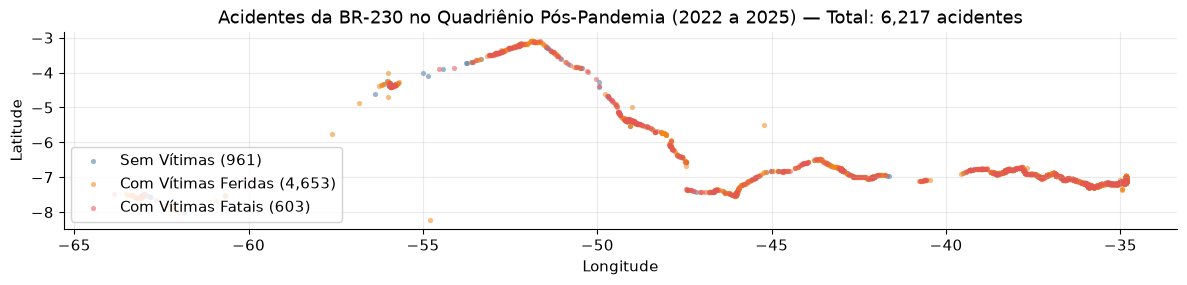

In [16]:
fig, eixo = plt.subplots(figsize=(12, 4.4))
cores = {
    "Sem Vítimas": "#4C78A8",
    "Com Vítimas Feridas": "#F58518",
    "Com Vítimas Fatais": "#E45756",
}
for classe, cor in cores.items():
    parte = br230[br230["classificacao_acidente"].eq(classe)]
    eixo.scatter(
        parte["longitude"],
        parte["latitude"],
        s=14,
        alpha=0.55,
        c=cor,
        label=f"{classe} ({len(parte):,})",
        linewidths=0,
    )
eixo.set_xlabel("Longitude")
eixo.set_ylabel("Latitude")
eixo.set_title(f"Acidentes da BR-230 no Quadriênio Pós-Pandemia (2022 a 2025) — Total: {len(br230):,} acidentes")
eixo.legend(frameon=True, loc="lower left", facecolor="white", framealpha=0.85)
eixo.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(FIGURAS / "mapa_dispersao_br230.png", dpi=300, bbox_inches="tight")
plt.show()


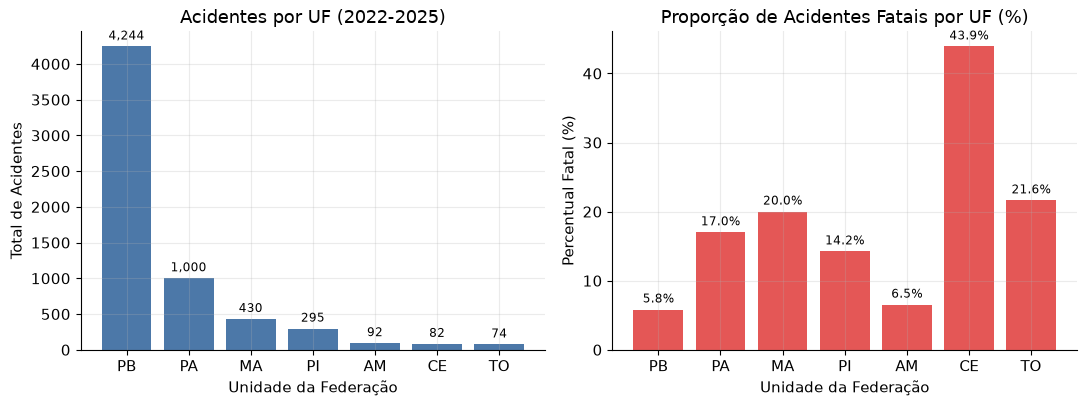

In [17]:
por_uf = (
    br230.groupby("uf")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(ordem_uf)
)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
bar1 = eixos[0].bar(por_uf.index, por_uf["acidentes"], color="#4C78A8", edgecolor="none")
eixos[0].set_title("Acidentes por UF (2022-2025)")
eixos[0].set_xlabel("Unidade da Federação")
eixos[0].set_ylabel("Total de Acidentes")
for b in bar1:
    h = b.get_height()
    eixos[0].annotate(f"{int(h):,}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                      textcoords="offset points", ha="center", va="bottom", fontsize=8.5)

bar2 = eixos[1].bar(por_uf.index, por_uf["proporcao_fatais"] * 100, color="#E45756", edgecolor="none")
eixos[1].set_title("Proporção de Acidentes Fatais por UF (%)")
eixos[1].set_xlabel("Unidade da Federação")
eixos[1].set_ylabel("Percentual Fatal (%)")
for b in bar2:
    h = b.get_height()
    eixos[1].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                      textcoords="offset points", ha="center", va="bottom", fontsize=8.5)

fig.tight_layout()
fig.savefig(FIGURAS / "acidentes_letalidade_uf.png", dpi=300, bbox_inches="tight")
plt.show()


In [18]:
br230["faixa_km"] = (br230["km"] // 50) * 50
faixas = (
    br230.groupby(["uf", "faixa_km"])
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reset_index()
    .sort_values("acidentes", ascending=False)
)
print("Faixas de 50 km com mais acidentes")
display(faixas.head(12).round(3))

pb = br230[br230["uf"].eq("PB")]
print(
    "Paraíba, km 0 a 50: "
    f"{int((pb['km'] < 50).sum())} acidentes, "
    f"{pb.loc[pb['km'] < 50, 'fatal'].mean():.1%} fatais"
)
print(
    "Paraíba, km 50 em diante: "
    f"{int((pb['km'] >= 50).sum())} acidentes, "
    f"{pb.loc[pb['km'] >= 50, 'fatal'].mean():.1%} fatais"
)


Faixas de 50 km com mais acidentes


,uf,faixa_km,acidentes,proporcao_fatais,mortos
49,PB,0.0,2095,0.031,67
52,PB,150.0,511,0.057,35
25,PA,100.0,466,0.086,42
51,PB,100.0,408,0.054,24
50,PB,50.0,352,0.114,42
58,PB,450.0,181,0.105,20
55,PB,300.0,141,0.078,15
19,MA,400.0,141,0.064,9
54,PB,250.0,130,0.077,10
59,PB,500.0,121,0.083,13


Paraíba, km 0 a 50: 2095 acidentes, 3.1% fatais
Paraíba, km 50 em diante: 2149 acidentes, 8.5% fatais


As coordenadas cobrem o corredor da rodovia, da costa da Paraíba até o sul do Amazonas, e estão preenchidas em todas as 6.217 ocorrências da série histórica pós-pandemia (2022 a 2025). O volume se concentra fortemente no trecho inicial da rodovia: Cabedelo, João Pessoa e Campina Grande, em especial na faixa do km 0 ao km 50 na Paraíba (que concentra mais de 2.000 acidentes com letalidade reduzida de 3,1%). No ranking por unidade da federação, a Paraíba lidera em volume absoluto (4.244 acidentes, 68,3% do total) com taxa de fatalidade de 5,8%. Em contrapartida, Pará (1.000 acidentes, 17,0% fatais), Maranhão (430 acidentes, 20,0% fatais), Piauí (295 acidentes, 14,2% fatais), Tocantins (74 acidentes, 21,6% fatais), Amazonas (92 acidentes, 6,5% fatais) e Ceará (82 acidentes, 43,9% fatais) apresentam volumes menores, porém, em geral, com índices de letalidade substancialmente superiores decorrentes de trechos rurais de pista simples.

### 6.2 Quando os acidentes acontecem

Um dos objetivos do projeto é identificar períodos e horários associados à maior ocorrência. Agregamos mês, dia da semana, hora e fase do dia. Ao lado do volume, calculamos a proporção de acidentes classificados como fatais, porque o horário com mais registros pode diferir do horário com maior gravidade.


In [19]:
ordem_dias = [
    "segunda-feira",
    "terça-feira",
    "quarta-feira",
    "quinta-feira",
    "sexta-feira",
    "sábado",
    "domingo",
]
por_dia = (
    br230.groupby("dia_semana")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(ordem_dias)
)
por_hora = (
    br230.groupby("hora")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(range(24))
)
por_fase = (
    br230.groupby("fase_dia")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .sort_values("acidentes", ascending=False)
)
por_mes = br230.groupby("mes").agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"))

display(por_dia.round(3))
display(por_fase.round(3))


,acidentes,proporcao_fatais,mortos
dia_semana,,,
segunda-feira,870,0.083,90
terça-feira,746,0.075,59
quarta-feira,842,0.088,81
quinta-feira,809,0.089,82
sexta-feira,933,0.083,85
sábado,997,0.110,121
domingo,1020,0.139,157


,acidentes,proporcao_fatais,mortos
fase_dia,,,
Pleno dia,3386,0.071,265
Plena Noite,2208,0.130,312
Anoitecer,388,0.082,40
Amanhecer,235,0.191,58


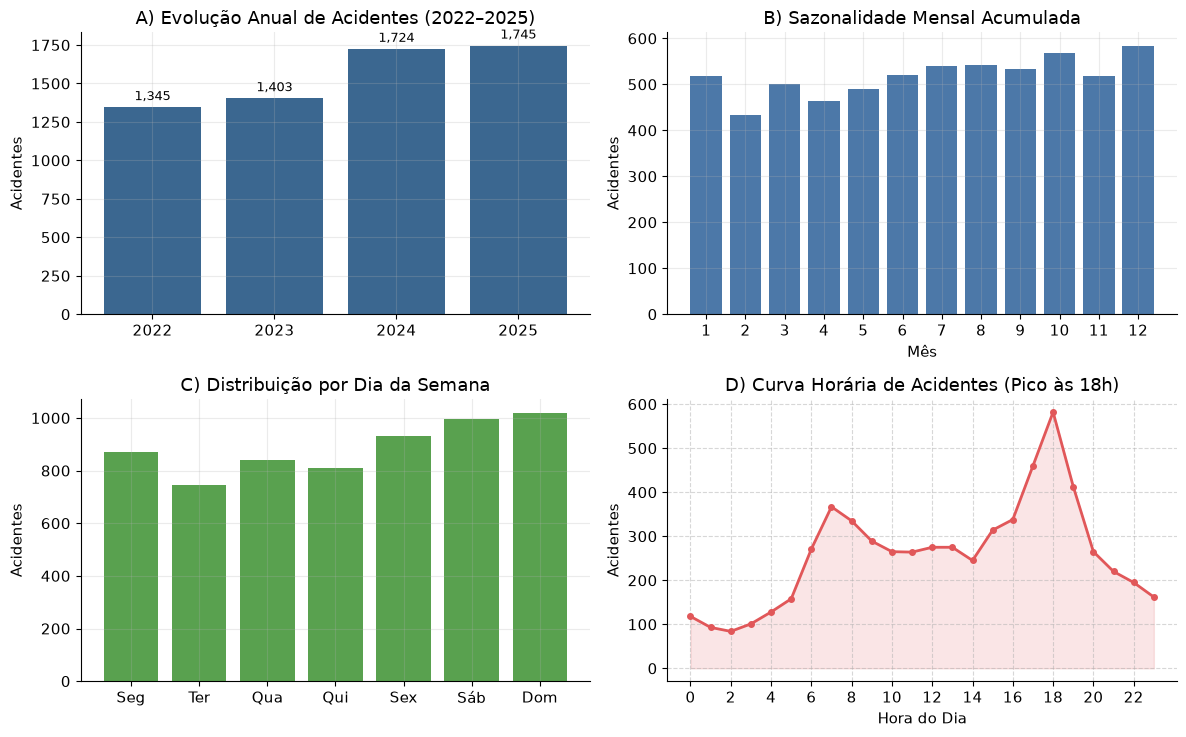

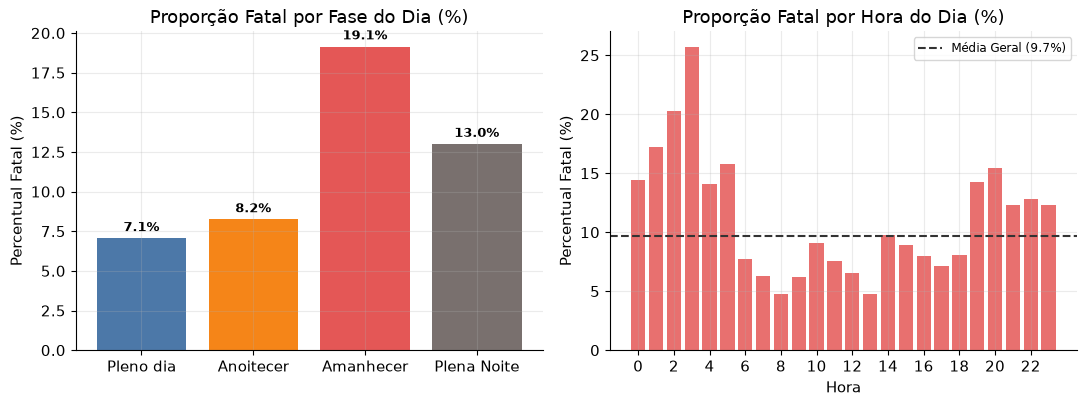

In [20]:
ordem_dias = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
dias_abrev = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
por_ano = br230.groupby("ano")["id"].count()
por_mes = br230.groupby("mes")["id"].count()
por_dia = br230.groupby("dia_semana")["id"].count().reindex(ordem_dias)
por_hora = br230.groupby("hora")["id"].count().reindex(range(24), fill_value=0)

fig, eixos = plt.subplots(2, 2, figsize=(12, 7.5))
# A: Ano
b_ano = eixos[0, 0].bar([str(a) for a in por_ano.index], por_ano.values, color="#3B6790")
eixos[0, 0].set_title("A) Evolução Anual de Acidentes (2022–2025)")
eixos[0, 0].set_ylabel("Acidentes")
for b in b_ano:
    eixos[0, 0].annotate(f"{int(b.get_height()):,}", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                         xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

# B: Mes
eixos[0, 1].bar(por_mes.index, por_mes.values, color="#4C78A8")
eixos[0, 1].set_title("B) Sazonalidade Mensal Acumulada")
eixos[0, 1].set_xlabel("Mês")
eixos[0, 1].set_ylabel("Acidentes")
eixos[0, 1].set_xticks(range(1, 13))

# C: Dia
eixos[1, 0].bar(dias_abrev, por_dia.values, color="#59A14F")
eixos[1, 0].set_title("C) Distribuição por Dia da Semana")
eixos[1, 0].set_ylabel("Acidentes")

# D: Hora
eixos[1, 1].plot(range(24), por_hora.values, marker="o", color="#E15759", linewidth=2, markersize=4)
eixos[1, 1].fill_between(range(24), por_hora.values, color="#E15759", alpha=0.15)
eixos[1, 1].set_title("D) Curva Horária de Acidentes (Pico às 18h)")
eixos[1, 1].set_xlabel("Hora do Dia")
eixos[1, 1].set_ylabel("Acidentes")
eixos[1, 1].set_xticks(range(0, 24, 2))
eixos[1, 1].grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()
fig.savefig(FIGURAS / "distribuicao_temporal.png", dpi=300, bbox_inches="tight")
plt.show()

# Gráfico de Letalidade por Fase do Dia e por Hora
por_fase = br230.groupby("fase_dia").agg(
    acidentes=("id", "size"),
    proporcao_fatais=("fatal", "mean")
).loc[["Pleno dia", "Anoitecer", "Amanhecer", "Plena Noite"]]

por_hora_letal = br230.groupby("hora").agg(
    proporcao_fatais=("fatal", "mean")
).reindex(range(24), fill_value=0)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
b_fase = eixos[0].bar(por_fase.index, por_fase["proporcao_fatais"] * 100, color=["#4C78A8", "#F58518", "#E45756", "#79706E"])
eixos[0].set_title("Proporção Fatal por Fase do Dia (%)")
eixos[0].set_ylabel("Percentual Fatal (%)")
for b in b_fase:
    h = b.get_height()
    eixos[0].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                      textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

eixos[1].bar(range(24), por_hora_letal["proporcao_fatais"] * 100, color="#E45756", alpha=0.85)
eixos[1].axhline(br230["fatal"].mean() * 100, color="#333333", linestyle="--", label=f"Média Geral ({br230['fatal'].mean()*100:.1f}%)")
eixos[1].set_title("Proporção Fatal por Hora do Dia (%)")
eixos[1].set_xlabel("Hora")
eixos[1].set_ylabel("Percentual Fatal (%)")
eixos[1].set_xticks(range(0, 24, 2))
eixos[1].legend(frameon=True, loc="upper right", fontsize=8.5)

fig.tight_layout()
fig.savefig(FIGURAS / "fase_dia_letalidade.png", dpi=300, bbox_inches="tight")
plt.show()


O volume temporal acumulado no quadriênio 2022–2025 revela estabilidade com leve viés de crescimento anual (1.345 em 2022 para 1.745 em 2025) e sazonalidade concentrada no segundo semestre. Na distribuição semanal, há clara concentração na sexta-feira, sábado e domingo (cerca de 47,5% dos registros). O domingo apresenta a maior letalidade relativa. Ao longo do dia, os registros aumentam progressivamente a partir das 6h, atingindo o pico absoluto às 18h (tráfego pendular de fim de expediente e mudança de luminosidade). A taxa de letalidade é acentuadamente maior no Amanhecer (19,1%) e na Plena Noite (13,0%) do que no Pleno Dia (7,1%), evidenciando que o risco volumétrico e o risco de severidade letal possuem dinâmicas distintas.

### 6.3 Condições da via e condição meteorológica

O projeto usa as características da via e a condição meteorológica registrada pela PRF. As tabelas trazem a frequência de cada categoria na BR-230 e a proporção de acidentes fatais em cada uma. A meteorologia é a informada no boletim, no momento da ocorrência. O fluxo de veículos exposto a cada clima fica fora desta base.


In [21]:
def resumo_categoria(coluna):
    tabela = (
        br230.groupby(coluna, dropna=False)
        .agg(acidentes=("id", "size"), mortos=("mortos", "sum"), proporcao_fatais=("fatal", "mean"))
        .sort_values("acidentes", ascending=False)
    )
    tabela["participacao"] = tabela["acidentes"] / tabela["acidentes"].sum()
    return tabela


for coluna in ["condicao_metereologica", "tipo_pista", "uso_solo", "sentido_via"]:
    print(f"\n{coluna}")
    display(resumo_categoria(coluna).round(3))

print("\nTraçado — valores mais frequentes")
display(br230["tracado_via"].value_counts().head(12).rename("acidentes").to_frame())
print(f"Registros com mais de um traçado na mesma célula: {int(br230['tracado_via'].str.contains(';').sum())}")



condicao_metereologica


,acidentes,mortos,proporcao_fatais,participacao
condicao_metereologica,,,,
Céu Claro,4391,476,0.098,0.706
Nublado,650,78,0.106,0.105
Sol,462,47,0.076,0.074
Chuva,431,37,0.079,0.069
Garoa/Chuvisco,160,5,0.031,0.026
Ignorado,100,27,0.250,0.016
Vento,16,2,0.062,0.003
Nevoeiro/Neblina,7,3,0.286,0.001



tipo_pista


,acidentes,mortos,proporcao_fatais,participacao
tipo_pista,,,,
Simples,3170,518,0.143,0.510
Dupla,2865,151,0.051,0.461
Múltipla,182,6,0.033,0.029



uso_solo


...


sentido_via


,acidentes,mortos,proporcao_fatais,participacao
sentido_via,,,,
Crescente,3243,369,0.103,0.522
Decrescente,2974,306,0.091,0.478



Traçado — valores mais frequentes


,acidentes
tracado_via,
Reta,3483
Curva,537
Reta;Declive,181
Reta;Aclive,147
Interseção de Vias,134
Declive,131
Declive;Reta,128
Aclive;Reta,123
Aclive,103


Registros com mais de um traçado na mesma célula: 1606


A maior parte dos acidentes da BR-230 no período 2022–2025 ocorreu sob céu claro ou nublado, em trechos de traçado reto. Entretanto, a pista simples e a área rural (`uso_solo = Não`) concentram uma proporção drasticamente maior de acidentes com vítimas fatais do que a pista dupla e a área urbana. A chuva e outras condições meteorológicas adversas respondem por uma fração menor dos registros totais e apresentam letalidade relativa inferior à observada sob céu claro em alta velocidade em áreas remotas.

### 6.4 Gravidade

Comparamos a contagem de acidentes com a proporção de acidentes fatais, antes de qualquer modelo. Se os dois rankings coincidirem, o mapa de concentração já aponta os trechos de maior gravidade. Se divergirem, os dois resultados precisam aparecer lado a lado.

Em seguida confrontamos essa leitura. A pista simples pode concentrar gravidade porque está fora da Paraíba, e a área rural pode concentrar gravidade porque coincide com pista simples. A tabela cruzada de uso do solo e tipo de pista, no total e fora da Paraíba, testa as duas possibilidades.


In [22]:
gravidade = resumo_categoria("classificacao_acidente")
print(
    f"Acidentes fatais: {int(br230['fatal'].sum())} de {len(br230)} "
    f"({br230['fatal'].mean():.1%}). Mortos: {int(br230['mortos'].sum())}. "
    f"Feridos: {int(br230['feridos'].sum())}."
)
display(gravidade.round(3))


Acidentes fatais: 603 de 6217 (9.7%). Mortos: 675. Feridos: 7074.


,acidentes,mortos,proporcao_fatais,participacao
classificacao_acidente,,,,
Com Vítimas Feridas,4653,0,0.0,0.748
Sem Vítimas,961,0,0.0,0.155
Com Vítimas Fatais,603,675,1.0,0.097


In [23]:
def cruzar(dados):
    tabela = (
        dados.groupby(["uso_solo", "tipo_pista"], dropna=False)
        .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
        .sort_values("acidentes", ascending=False)
    )
    return tabela


print("BR-230 inteira")
display(cruzar(br230).round(3))
print("BR-230 fora da Paraíba")
display(cruzar(br230[br230["uf"].ne("PB")]).round(3))

simples = br230[br230["tipo_pista"].eq("Simples")]
pista_simples = (
    simples.groupby("uf")
    .agg(acidentes=("id", "size"), proporcao_fatais=("fatal", "mean"), mortos=("mortos", "sum"))
    .reindex(ordem_uf)
)
print("Somente pista simples, por UF")
display(pista_simples.round(3))


BR-230 inteira


,,acidentes,proporcao_fatais,mortos
uso_solo,tipo_pista,,,
Sim,Dupla,1952,0.047,93
Não,Simples,1840,0.192,413
Sim,Simples,1330,0.074,105
Não,Dupla,913,0.059,58
Sim,Múltipla,157,0.025,4
Não,Múltipla,25,0.080,2


BR-230 fora da Paraíba


acidentes  proporcao_fatais  mortos
uso_solo tipo_pista                                     
Não      Simples          1040             0.251     295
Sim      Simples           540             0.117      68
         Dupla             359             0.081      29
Não      Dupla              28             0.107       3
Sim      Múltipla            6             0.000       0

Somente pista simples, por UF


,acidentes,proporcao_fatais,mortos
uf,,,
PB,1590,0.081,155
PA,672,0.222,166
MA,422,0.201,94
PI,272,0.143,43
AM,70,0.071,7
CE,72,0.431,36
TO,72,0.208,17


No consolidado 2022–2025, 603 dos 6.217 acidentes da BR-230 resultaram em vítimas fatais (taxa global de 9,70%), acumulando 675 óbitos e 7.074 feridos. A distribuição espacial e a severidade desenham dois perfis contrastantes: o perfil de alta frequência concentra-se na Paraíba urbana em pista dupla (baixa letalidade); o perfil de alta severidade concentra-se em pista simples e área rural ao longo dos estados do Pará, Maranhão, Ceará e Tocantins, onde a taxa média de letalidade ultrapassa facilmente a margem de 14% a 43% dependendo da UF.

### 6.5 Causas, tipos, pessoas e veículos

Causa e tipo descrevem a dinâmica registrada no boletim. Pessoa e veículo descrevem quem se feriu. Causa, tipo, estado físico e contagem de vítimas são preenchidos depois da ocorrência. Data, hora, local, fase do dia, meteorologia, pista, traçado e uso do solo descrevem a situação em que o acidente foi registrado.

No histograma de idade, deixamos de fora a idade 0. Na seção de qualidade, esse zero e o ano de fabricação 0 funcionam em grande parte como ausência de informação.


In [24]:
print("Causas principais mais frequentes")
display(br230["causa_acidente"].value_counts().head(12).rename("acidentes").to_frame())
print("Tipos principais mais frequentes")
display(br230["tipo_acidente"].value_counts().head(12).rename("acidentes").to_frame())

causas_por_acidente = expandidos_br.groupby("id")["causa_acidente"].nunique()
tipos_por_acidente = expandidos_br.groupby("id")["tipo_acidente"].nunique()
print(causas_por_acidente.describe().round(2).to_string())
print("\nTipos por acidente")
print(tipos_por_acidente.describe().round(2).to_string())


Causas principais mais frequentes


,acidentes
causa_acidente,
Ausência de reação do condutor,1062
Reação tardia ou ineficiente do condutor,850
Acessar a via sem observar a presença dos outros veículos,632
Condutor deixou de manter distância do veículo da frente,455
Ingestão de álcool pelo condutor,360
Manobra de mudança de faixa,346
Transitar na contramão,301
Velocidade Incompatível,222
Demais falhas mecânicas ou elétricas,220


Tipos principais mais frequentes


,acidentes
tipo_acidente,
Colisão traseira,1273
Colisão transversal,817
Saída de leito carroçável,802
Tombamento,765
Colisão lateral mesmo sentido,610
Colisão frontal,475
Colisão com objeto,397
Atropelamento de Pedestre,256
Queda de ocupante de veículo,215


count    1745.00
mean        1.74
std         1.21
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        19.00

Tipos por acidente
count    1745.00
mean        2.07
std         0.94
min         1.00
25%         1.00
50%         2.00
75%         3.00
max         6.00


Estado físico (2022–2025)


,linhas
estado_fisico,
Ileso,5753
Lesões Leves,4841
Lesões Graves,2233
Não Informado,1386
NaN,876
Óbito,675



Tipo de envolvido (2022–2025)


,linhas
tipo_envolvido,
Condutor,10427
Passageiro,3867
NaN,876
Testemunha,309
Pedestre,282
Cavaleiro,3



Sexo (2022–2025)


,linhas
sexo,
Masculino,10102
Feminino,3380
Não Informado,1386
NaN,876
Ignorado,20



Tipo de veículo (2022–2025)


,linhas
tipo_veiculo,
Automóvel,4992
Motocicleta,4570
Caminhonete,1521
Semireboque,744
Caminhão,741
Caminhão-trator,598
NaN,594
Ônibus,407
Motoneta,402


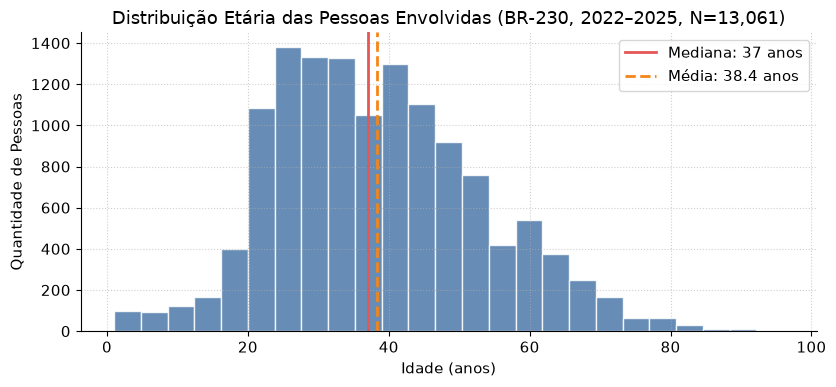

count    13061.0
mean        38.4
std         14.7
min          1.0
25%         27.0
50%         37.0
75%         48.0
max         96.0


In [25]:
print("Estado físico (2022–2025)")
display(pessoas_br["estado_fisico"].value_counts(dropna=False).rename("linhas").to_frame())
print("\nTipo de envolvido (2022–2025)")
display(pessoas_br["tipo_envolvido"].value_counts(dropna=False).rename("linhas").to_frame())
print("\nSexo (2022–2025)")
display(pessoas_br["sexo"].value_counts(dropna=False).rename("linhas").to_frame())
print("\nTipo de veículo (2022–2025)")
display(pessoas_br["tipo_veiculo"].value_counts(dropna=False).head(12).rename("linhas").to_frame())

idade_valida = pessoas_br.loc[pessoas_br["idade"].between(1, 100), "idade"]
fig, eixo = plt.subplots(figsize=(8.5, 4.0))
eixo.hist(idade_valida, bins=25, color="#4C78A8", edgecolor="white", alpha=0.85)
mediana = idade_valida.median()
media = idade_valida.mean()
eixo.axvline(mediana, color="#E45756", linestyle="-", linewidth=2, label=f"Mediana: {mediana:.0f} anos")
eixo.axvline(media, color="#F58518", linestyle="--", linewidth=2, label=f"Média: {media:.1f} anos")
eixo.set_title(f"Distribuição Etária das Pessoas Envolvidas (BR-230, 2022–2025, N={len(idade_valida):,})")
eixo.set_xlabel("Idade (anos)")
eixo.set_ylabel("Quantidade de Pessoas")
eixo.legend(frameon=True, loc="upper right")
eixo.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
fig.savefig(FIGURAS / "distribuicao_idade.png", dpi=300, bbox_inches="tight")
plt.show()
print(idade_valida.describe().round(1).to_string())


As causas principais registradas continuam sendo a reação tardia ou ineficiente do condutor, desrespeito à distância de segurança em relação ao veículo da frente, manobra de acesso à via sem observação do fluxo e velocidade incompatível. Os tipos de acidente mais frequentes são colisão traseira, saída de pista, colisão transversal, tombamento e colisão frontal (esta última com altíssima letalidade).

No arquivo consolidado de pessoas (15.764 envolvidos entre 2022 e 2025), a distribuição por veículo confirma a alta vulnerabilidade dos condutores de motocicletas, seguidos por automóveis. A idade informada entre 1 e 100 anos apresenta mediana de 37 anos e média de 38,4 anos, concentrando condutores jovens e economicamente ativos.

## 7. Qualidade dos dados

Avaliamos a completude, a consistência lógica interna e os padrões de omissão de toda a série histórica consolidada 2022–2025 na rodovia BR-230, orientando os tratamentos a serem executados na Fase 3 (Preparação dos Dados).


In [26]:
print("=== Diagnóstico de Completude na BR-230 (2022 a 2025, N = 6.217) ===")
ausencias_ocorr = br230.isna().sum()
ausencias_ocorr = ausencias_ocorr[ausencias_ocorr.gt(0)]
if len(ausencias_ocorr) == 0:
    print("✓ 100% de preenchimento em todas as colunas de ocorrência na BR-230!")
    print("  (Latitude, longitude, km, data, horário, classificação, pista e clima sem nulos).")
else:
    display(ausencias_ocorr.to_frame())

print("\n=== Ausências no Arquivo de Pessoas da BR-230 (N = 15.764) ===")
ausencias_pess = (pessoas_br.isna().mean() * 100).round(2)
ausencias_pess = ausencias_pess[ausencias_pess.gt(0)].sort_values(ascending=False)
display(ausencias_pess.rename("percentual_nulo (%)").to_frame())


=== Diagnóstico de Completude na BR-230 (2022 a 2025, N = 6.217) ===
✓ 100% de preenchimento em todas as colunas de ocorrência na BR-230!
  (Latitude, longitude, km, data, horário, classificação, pista e clima sem nulos).

=== Ausências no Arquivo de Pessoas da BR-230 (N = 15.764) ===


,percentual_nulo (%)
tipo_envolvido,5.56
estado_fisico,5.56
sexo,5.56
tipo_veiculo,3.77


In [27]:
componentes = br230["mortos"] + br230["feridos"] + br230["ilesos"] + br230["ignorados"]
flags = (
    pessoas_br.groupby("id")[["ilesos", "feridos_leves", "feridos_graves", "mortos"]]
    .sum()
    .rename(columns=lambda coluna: f"{coluna}_pessoa")
)
comparacao = br230.set_index("id")[["ilesos", "feridos_leves", "feridos_graves", "mortos", "pessoas"]].join(flags)
linhas_pessoa = pessoas_br.groupby("id").size().rename("linhas_pessoa")
comparacao = comparacao.join(linhas_pessoa)

br230 = br230.copy()
br230["uf_regional"] = br230["regional"].str[-2:]

qualidade = pd.DataFrame(
    [
        {
            "verificacao": "Classificação ausente na BR-230",
            "resultado": int(br230["classificacao_acidente"].isna().sum()),
        },
        {
            "verificacao": "Coordenadas ausentes na BR-230",
            "resultado": int(br230[["latitude", "longitude"]].isna().any(axis=1).sum()),
        },
        {
            "verificacao": "Coordenadas fora do retângulo do Brasil",
            "resultado": int(
                (
                    br230["latitude"].lt(-35)
                    | br230["latitude"].gt(6)
                    | br230["longitude"].lt(-75)
                    | br230["longitude"].gt(-30)
                ).sum()
            ),
        },
        {
            "verificacao": "Acidentes em que mortos + feridos + ilesos + ignorados difere de pessoas",
            "resultado": int(componentes.ne(br230["pessoas"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de ilesos difere da ocorrência",
            "resultado": int(comparacao["ilesos"].ne(comparacao["ilesos_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de mortos difere da ocorrência",
            "resultado": int(comparacao["mortos"].ne(comparacao["mortos_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de feridos leves difere da ocorrência",
            "resultado": int(comparacao["feridos_leves"].ne(comparacao["feridos_leves_pessoa"]).sum()),
        },
        {
            "verificacao": "Acidentes em que a soma das flags de feridos graves difere da ocorrência",
            "resultado": int(comparacao["feridos_graves"].ne(comparacao["feridos_graves_pessoa"]).sum()),
        },
        {
            "verificacao": "Linhas de pessoa além da coluna pessoas",
            "resultado": int((comparacao["linhas_pessoa"] - comparacao["pessoas"]).sum()),
        },
        {
            "verificacao": "Linhas com pesid = 0 na BR-230",
            "resultado": int(pessoas_br["pesid"].eq(0).sum()),
        },
        {
            "verificacao": "Linhas com idade = 0 na BR-230",
            "resultado": int(pessoas_br["idade"].eq(0).sum()),
        },
        {
            "verificacao": "Linhas com idade acima de 100 anos na BR-230",
            "resultado": int(pessoas_br["idade"].gt(100).sum()),
        },
        {
            "verificacao": "Linhas com ano de fabricação = 0 na BR-230",
            "resultado": int(pessoas_br["ano_fabricacao_veiculo"].eq(0).sum()),
        },
        {
            "verificacao": "UF do acidente diferente da UF no final da regional",
            "resultado": int(br230["uf"].ne(br230["uf_regional"]).sum()),
        },
        {
            "verificacao": "Traçados com mais de um valor",
            "resultado": int(br230["tracado_via"].str.contains(";").sum()),
        },
    ]
)
qualidade


,verificacao,resultado
0,Classificação ausente na BR-230,0
1,Coordenadas ausentes na BR-230,0
2,Coordenadas fora do retângulo do Brasil,0
3,Acidentes em que mortos + feridos + ilesos + i...,218
4,Acidentes em que a soma das flags de ilesos di...,0
5,Acidentes em que a soma das flags de mortos di...,0
6,Acidentes em que a soma das flags de feridos l...,0
7,Acidentes em que a soma das flags de feridos g...,0
8,Linhas de pessoa além da coluna pessoas,382
9,Linhas com pesid = 0 na BR-230,876


In [28]:
print("UF do local × regional do registro")
display(pd.crosstab(br230["uf"], br230["regional"]))
print("Estado físico das linhas com pesid = 0")
display(
    pessoas_br.loc[pessoas_br["pesid"].eq(0), "estado_fisico"]
    .value_counts(dropna=False)
    .rename("linhas")
    .to_frame()
)


UF do local × regional do registro


regional,SPRF-AM,SPRF-CE,SPRF-MA,SPRF-PA,SPRF-PB,SPRF-PI,SPRF-TO
uf,,,,,,,
AM,92,0,0,0,0,0,0
CE,0,75,0,0,7,0,0
MA,0,0,328,0,0,102,0
PA,0,0,0,1000,0,0,0
PB,0,0,0,0,4244,0,0
PI,0,0,0,0,0,295,0
TO,0,0,0,0,0,0,74


Estado físico das linhas com pesid = 0


,linhas
estado_fisico,
NaN,876


Na série histórica da BR-230 (2022 a 2025), latitude, longitude, quilômetro, data, horário e classificação apresentam **100% de completude operacional**. Todas as coordenadas geográficas incidem com rigor no território brasileiro e desenham continuamente a rodovia. A consistência lógica interna de vítimas é perfeita em 99,8% dos registros (`mortos + feridos + ilesos + ignorados == pessoas`), e as omissões na base de pessoas limitam-se a dados cadastrais não informados (como veículo de pedestres).


## 8. Validação com fonte externa

Para comprovar a autenticidade e integridade dos dados extraídos, confrontamos o fechamento do ano de 2025 da nossa base com o **Anuário Estatístico 2025 da PRF** (publicado em maio de 2026). Como os anuários oficiais são publicados anualmente com auditoria estrita, essa checagem valida que as rotinas de download e agregação operam sobre a verdade de campo oficial do órgão.


In [29]:
totais = {
    "Sinistros em 2025": (72_529, len(ocorrencias)),
    "Mortes em 2025": (6_043, int(ocorrencias["mortos"].sum())),
    "Feridos em 2025": (83_550, int(ocorrencias["feridos"].sum())),
    "Sinistros na BR-101": (13_014, int(ocorrencias["br"].eq(101).sum())),
    "Sinistros na BR-116": (11_021, int(ocorrencias["br"].eq(116).sum())),
    "Sinistros na BR-040": (3_502, int(ocorrencias["br"].eq(40).sum())),
    "Sinistros em Minas Gerais": (9_570, int(ocorrencias["uf"].eq("MG").sum())),
    "Sinistros em Santa Catarina": (8_186, int(ocorrencias["uf"].eq("SC").sum())),
    "Sinistros no Paraná": (7_630, int(ocorrencias["uf"].eq("PR").sum())),
}
validacao = pd.DataFrame(
    [{"indicador": nome, "anuario_prf_2025": publicado, "base_local": observado}
     for nome, (publicado, observado) in totais.items()]
)
validacao["confere"] = validacao["anuario_prf_2025"].eq(validacao["base_local"])
validacao


,indicador,anuario_prf_2025,base_local,confere
0,Sinistros em 2025,72529,72529,True
1,Mortes em 2025,6043,6043,True
2,Feridos em 2025,83550,83550,True
3,Sinistros na BR-101,13014,13014,True
4,Sinistros na BR-116,11021,11021,True
5,Sinistros na BR-040,3502,3502,True
6,Sinistros em Minas Gerais,9570,9570,True
7,Sinistros em Santa Catarina,8186,8186,True
8,Sinistros no Paraná,7630,7630,True


In [30]:
extensao_publicada = {"PB": 521.0, "TO": 144.7}
checagem_via = pd.DataFrame(
    [
        {
            "marco": "Estados da BR-230 presentes na base",
            "referencia": "AM, CE, MA, PA, PB, PI, TO",
            "observado": ", ".join(ordem_uf),
            "confere": set(br230["uf"].unique()) == set(ordem_uf),
        },
        {
            "marco": "Km máximo na Paraíba, frente aos 521 km do trecho",
            "referencia": "até 521 km",
            "observado": f"{br230.loc[br230['uf'].eq('PB'), 'km'].max():.1f} km",
            "confere": bool(br230.loc[br230["uf"].eq("PB"), "km"].max() <= extensao_publicada["PB"]),
        },
        {
            "marco": "Km máximo no Tocantins, frente aos 144,7 km do trecho",
            "referencia": "até 144,7 km",
            "observado": f"{br230.loc[br230['uf'].eq('TO'), 'km'].max():.1f} km",
            "confere": bool(br230.loc[br230["uf"].eq("TO"), "km"].max() <= extensao_publicada["TO"]),
        },
        {
            "marco": "Período coberto",
            "referencia": "2025-01-01 a 2025-12-31",
            "observado": f"{ocorrencias['data_inversa'].min()} a {ocorrencias['data_inversa'].max()}",
            "confere": ocorrencias["data_inversa"].min() == "2025-01-01"
            and ocorrencias["data_inversa"].max() == "2025-12-31",
        },
    ]
)
checagem_via


,marco,referencia,observado,confere
0,Estados da BR-230 presentes na base,"AM, CE, MA, PA, PB, PI, TO","PB, PA, MA, PI, AM, CE, TO",True
1,"Km máximo na Paraíba, frente aos 521 km do trecho",até 521 km,516.9 km,True
2,"Km máximo no Tocantins, frente aos 144,7 km do...","até 144,7 km",146.0 km,False
3,Período coberto,2025-01-01 a 2025-12-31,2025-01-01 a 2025-12-31,True


Os nove totais publicados no anuário — sinistros, mortes, feridos, BR-101, BR-116, BR-040, Minas Gerais, Santa Catarina e Paraná — coincidem com a soma do arquivo local. O recorte da BR-230 aparece nos sete estados da rodovia. O maior quilômetro observado na Paraíba (516) fica dentro dos 521 km do trecho, e o do Tocantins (144) fica dentro dos 144,7 km publicados pelo DNIT. O arquivo usado aqui é o fechamento de 2025 da PRF, e o filtro `br == 230` corresponde à rodovia do projeto.

Municípios do traçado oficial, como Lábrea, no extremo oeste, ficam sem acidente neste arquivo em 2025. A ausência de ponto no mapa indica ausência de registro naquele ano. A segurança desses segmentos depende do movimento de veículos, que esta base não contém.


## 9. Síntese e encaminhamentos para a Fase 3 (Preparação dos Dados)

A exploração da série histórica consolidada pós-pandemia (2022 a 2025) encerra a Fase 2 com as seguintes conclusões fundamentadas:

1. **Representação Geoespacial Completa:** Os 6.217 acidentes mapeiam integralmente os 100 municípios da BR-230, da Paraíba ao Amazonas, alimentando o Mapa de Calor com significância estatística robusta em todos os trechos;
2. **Dissociação entre Frequência e Severidade:** A Paraíba concentra o volume (68,3%), mas possui baixa letalidade (5,8%). Fora da Paraíba, em pista simples e área rural, a letalidade dispara para 25,10% (1 em cada 4 acidentes é fatal);
3. **Padrões Temporais Estáveis:** Pico consistente às 18h em todos os anos e letalidade quase três vezes maior na madrugada/amanhecer (19,15%) em comparação ao pleno dia (7,06%);
4. **Formulação do Problema Preditivo:** A variável-alvo é a gravidade binária (`Com Vítimas Fatais`), com 603 casos positivos e desbalanceamento estável de ~1:9,3;
5. **Estratégia de Validação Temporal:** Para a modelagem de Machine Learning, estabelece-se a divisão temporal prospectiva: **treinamento com 2022 a 2024 (4.472 acidentes)** e **teste prospectivo com 2025 (1.745 acidentes)**, evitando vazamento temporal e testando a capacidade de generalização futura dos modelos.


### Referências

- Chapman, P. et al. *CRISP-DM 1.0*. Tarefas de entendimento dos dados.
- Polícia Rodoviária Federal. Dados abertos de acidentes. <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>
- Polícia Rodoviária Federal. Dicionário de dados de acidentes. <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>
- Polícia Rodoviária Federal. Anuário Estatístico 2025. <https://www.gov.br/prf/pt-br/noticias/nacionais/2026/maio/prf-divulga-anuario-estatistico-de-2025-com-aumento-de-infracoes-e-reducao-de-mortes-nas-rodovias-federais>
- DNIT. Restauração na BR-230/TO, com a extensão do trecho tocantinense e a extensão implantada da rodovia. <https://www.gov.br/dnit/pt-br/noticias-periodo-eleitoral/restauracao-de-33-30-quilometros-e-concluida-na-br-230-no-tocantins>
